# Экспериментальное исследование влияния параметров алгоритмов хранения паролей на вычислительные затраты

## Импорт библиотек

In [13]:
import time
import os
import hashlib
import warnings

import bcrypt
from argon2 import PasswordHasher
from argon2.low_level import hash_secret_raw, Type
import psutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
warnings.filterwarnings('ignore')

%matplotlib inline 

plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

In [ ]:
passwords = []

with open("input_data/passwords.txt", 'r', encoding='utf-8') as f:
    for pwd in f:
        passwords.append(pwd[:-1])

    

## Функция замеров

In [7]:
def measure_memory_and_time(process, func, *args, **kwargs):
    mem_before = process.memory_info().rss / (1024 * 1024)

    start_time = time.perf_counter()
    result = func(*args, **kwargs)
    end_time = time.perf_counter()

    mem_after = process.memory_info().rss / (1024 * 1024)

    time_ms = (end_time - start_time) * 1000
    memory_mb = max(0, mem_after - mem_before)

    return result, time_ms, memory_mb

## Эксперимент

### Bcrypt

In [10]:
def hash_bcrypt(password, cost_factor):
    salt = bcrypt.gensalt(rounds=cost_factor)
    return bcrypt.hashpw(password.encode('utf-8'), salt)

In [11]:
def run_bcrypt_experiment(passwords, cost_factors, repeats=100):
    results = []

    process = psutil.Process(os.getpid())

    for cost in cost_factors:
        print(f"Тестируем bcrypt с cost={cost}...")

        times = []
        memories = []

        for i in range(repeats):

            pwd = passwords[i % len(passwords)]

            res, time_res, mem_res = measure_memory_and_time(process, hash_bcrypt, pwd, cost)

            times.append(time_res)
            memories.append(mem_res)

        median_time = np.median(times)
        max_memory = max(memories)

        results.append({
            'algorithm': 'bcrypt',
            'parameter_name': 'cost_factor',
            'parameter_value': cost,
            'time_ms': round(median_time, 3),
            'memory_mb': round(max_memory, 3)
        })

    return results

In [14]:
cost_factors_to_test = [4, 6, 8, 10, 12]

bcrypt_results = run_bcrypt_experiment(passwords, cost_factors_to_test, repeats=100)

Тестируем bcrypt с cost=4...
Тестируем bcrypt с cost=6...
Тестируем bcrypt с cost=8...
Тестируем bcrypt с cost=10...
Тестируем bcrypt с cost=12...


In [15]:
df_bcrypt = pd.DataFrame(bcrypt_results)
df_bcrypt.to_csv('results/bcrypt_results.csv', index=False)
df_bcrypt

,algorithm,parameter_name,parameter_value,time_ms,memory_mb
0,bcrypt,cost_factor,4,0.749,0
1,bcrypt,cost_factor,6,2.911,0
2,bcrypt,cost_factor,8,10.985,0
3,bcrypt,cost_factor,10,41.847,0
4,bcrypt,cost_factor,12,167.693,0


### Argon2

In [16]:
def hash_argon2(password, memory_cost, time_cost=3):
    ph = PasswordHasher(time_cost=time_cost, memory_cost=memory_cost)
    return ph.hash(password)

In [17]:
def run_argon2_experiment(passwords, memory_costs, repeats=100):
    results = []
    process = psutil.Process(os.getpid())

    for mem_cost in memory_costs:
        print(f"Тестируем Argon2 с memory_cost={mem_cost} КБ...")
        times = []
        memories = []
        
        for i in range(repeats):
            pwd = passwords[i % len(passwords)]

            res, time_res, mem_res = measure_memory_and_time(process, hash_argon2, pwd, mem_cost)

            times.append(time_res)
            memories.append(mem_res)
            
        median_time = np.median(times)
        max_memory = max(memories)
        
        results.append({
            'algorithm': 'Argon2',
            'parameter_name': 'memory_cost_kb',
            'parameter_value': mem_cost,
            'time_ms': round(median_time, 3),
            'memory_mb': round(max_memory, 3)
        })
    
    return results

In [18]:
memory_costs_to_test = [16384, 32768, 65536, 131072] # 16 МБ, 32 МБ, 64 МБ и 128 МБ соответсвенно
argon2_results = run_argon2_experiment(passwords, memory_costs_to_test, repeats=100)

df_argon2 = pd.DataFrame(argon2_results)
df_argon2.to_csv('results/argon2_results.csv', index=False)
df_argon2

Тестируем Argon2 с memory_cost=16384 КБ...
Тестируем Argon2 с memory_cost=32768 КБ...
Тестируем Argon2 с memory_cost=65536 КБ...
Тестируем Argon2 с memory_cost=131072 КБ...


,algorithm,parameter_name,parameter_value,time_ms,memory_mb
0,Argon2,memory_cost_kb,16384,8.216,0.074
1,Argon2,memory_cost_kb,32768,14.491,0.004
2,Argon2,memory_cost_kb,65536,33.881,0.004
3,Argon2,memory_cost_kb,131072,63.855,0.000


### PBKDF2

In [22]:
def hash_pbkdf2(password, iterations):
    salt = b'some_fixed_salt_123'
    return hashlib.pbkdf2_hmac('sha256', password.encode('utf-8'), salt, iterations)

In [20]:
def run_pbkdf2_experiment(passwords, iterations_list, repeats=100):
    results = []
    process = psutil.Process(os.getpid())
    
    for iters in iterations_list:
        print(f"Тестируем PBKDF2 с iterations={iters}...")
        times = []
        
        for i in range(repeats):
            pwd = passwords[i % len(passwords)]
            res, time_res, _ = measure_memory_and_time(process, hash_pbkdf2, pwd, iters)
            times.append(time_res)
            
        median_time = np.median(times)
        
        results.append({
            'algorithm': 'PBKDF2',
            'parameter_name': 'iterations',
            'parameter_value': iters,
            'time_ms': round(median_time, 3)
        })
    return results

In [23]:
iterations_to_test = [10000, 50000, 100000, 200000, 500000]
pbkdf2_results = run_pbkdf2_experiment(passwords, iterations_to_test, repeats=100)

df_pbkdf2 = pd.DataFrame(pbkdf2_results)
df_pbkdf2.to_csv('results/pbkdf2_results.csv', index=False)
df_pbkdf2

Тестируем PBKDF2 с iterations=10000...
Тестируем PBKDF2 с iterations=50000...
Тестируем PBKDF2 с iterations=100000...
Тестируем PBKDF2 с iterations=200000...
Тестируем PBKDF2 с iterations=500000...


,algorithm,parameter_name,parameter_value,time_ms
0,PBKDF2,iterations,10000,3.578
1,PBKDF2,iterations,50000,16.308
2,PBKDF2,iterations,100000,32.477
3,PBKDF2,iterations,200000,64.860
4,PBKDF2,iterations,500000,162.282


## Вывод результатов

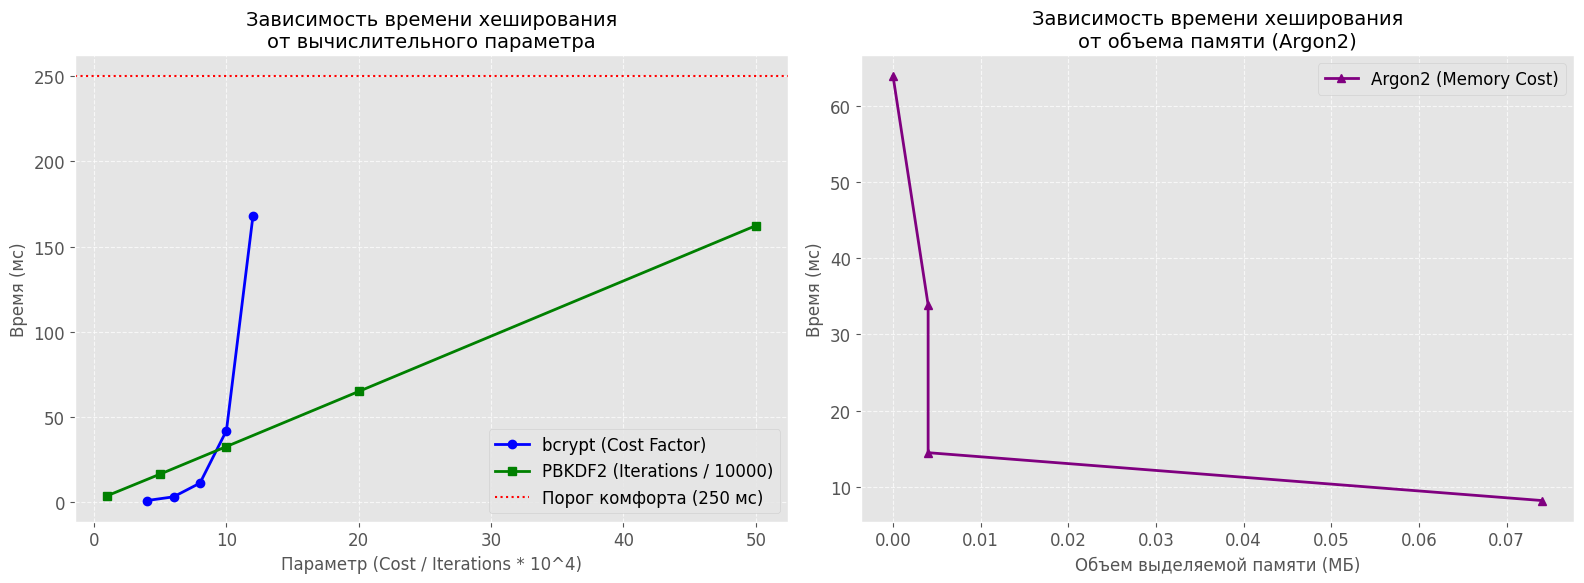

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax1 = axes[0]
ax1.plot(df_bcrypt['parameter_value'], df_bcrypt['time_ms'], marker='o', linewidth=2, color='blue', label='bcrypt (Cost Factor)')
ax1.plot(df_pbkdf2['parameter_value'] / 10000, df_pbkdf2['time_ms'], marker='s', linewidth=2, color='green', label='PBKDF2 (Iterations / 10000)')

ax1.set_title('Зависимость времени хеширования\nот вычислительного параметра', fontsize=14)
ax1.set_xlabel('Параметр (Cost / Iterations * 10^4)', fontsize=12)
ax1.set_ylabel('Время (мс)', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.7)
ax1.legend()

ax1.axhline(y=250, color='red', linestyle=':', label='Порог комфорта (250 мс)')
ax1.legend()

ax2 = axes[1]

ax2.plot(df_argon2['memory_mb'], df_argon2['time_ms'], marker='^', linewidth=2, color='purple', label='Argon2 (Memory Cost)')

ax2.set_title('Зависимость времени хеширования\nот объема памяти (Argon2)', fontsize=14)
ax2.set_xlabel('Объем выделяемой памяти (МБ)', fontsize=12)
ax2.set_ylabel('Время (мс)', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.7)
ax2.legend()

plt.tight_layout()
plt.savefig('figures/comparison_plots.png', dpi=300)
plt.show()